# Do trabeculae keep the heart from sticking? A walkthrough

This notebook walks through the reasoning, the models and the results of the study, tier by tier. The cheap parts are recomputed live (Tier 1 and the calibrated reduced model from Tier 3), and the expensive simulations (the 2D ventricle and the resolved 3D runs, hours of compute each) are loaded from the saved results in `results/`. Every number quoted in the slides can be traced to a cell here.

**Run it** from the repository root with `pip install -r requirements.txt notebook` and `jupyter notebook notebooks/walkthrough.ipynb`. The whole notebook runs in about a minute. To regenerate the saved results from scratch: `python -m squeeze_film.experiments`, `python -m ventricle.run` then `python -m ventricle.analyze`, and `python -m apex3d.run` then `python -m apex3d.analyze`. The test suite is `pytest`.

**Contents.** 1. The question and the physics. 2. Prior work. 3. Tier 1, the lubrication film. 4. Tier 2, the 2D ventricle. 5. Tier 3, 3D apposed walls and wall dynamics. 6. Verdict, limits, references.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Video, display, Markdown

from squeeze_film import reynolds as rf
from apex3d.reduced import FilmModel, open_walls, recoil, time_to_gap

MMHG = rf.MMHG
T1 = json.load(open("results/results.json"))
T2 = json.load(open("results/tier2_results.json"))
T3 = json.load(open("results/tier3_results.json"))
fig = lambda name, w=820: display(Image(filename=f"figures/{name}", width=w))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("blood viscosity", rf.MU_BLOOD * 1e3, "mPa s; density", rf.RHO_BLOOD, "kg/m^3")

blood viscosity 3.5 mPa s; density 1060.0 kg/m^3


## 1. The question and the physics

Textbooks sometimes say the trabeculae carneae stop the ventricular walls from sticking together by suction. Written as physics, the claim is about a **squeeze film** (Stefan adhesion): at end systole the apical walls come within a fraction of a millimetre, and in early diastole viscous blood has to flow sideways into that thin gap before the walls can separate. For a smooth disk of radius $R$ opening at speed $\dot h$ across a gap $h$, the suction at the centre is

$$\Delta p = \frac{3\mu R^2 \dot h}{h^3}.$$

The $h^{-3}$ is the whole story. The cell below evaluates it at the baseline values we used ($\mu$ = 3.5 mPa s, $R$ = 10 mm, $\dot h$ = 5 cm/s) and compares it with the roughly 2.5 mmHg base to apex gradient that drives early filling.

In [2]:
R, HDOT = 10e-3, 0.05
for h_mm in (1.0, 0.5, 0.2, 0.1):
    dp = -rf.disk_center_pressure(R, h_mm * 1e-3, HDOT) / MMHG
    print(f"gap {h_mm:4.1f} mm  ->  centre suction {dp:7.1f} mmHg")
print("available early diastolic gradient ~ 2.5 mmHg")

gap  1.0 mm  ->  centre suction     0.4 mmHg
gap  0.5 mm  ->  centre suction     3.2 mmHg
gap  0.2 mm  ->  centre suction    49.2 mmHg
gap  0.1 mm  ->  centre suction   393.8 mmHg
available early diastolic gradient ~ 2.5 mmHg


**Hypothesis.** The grooves between trabeculae act as drainage channels, so blood only travels across a short land between grooves rather than across the whole wall, and the suction collapses. The three tiers test whether that is true (Tier 1), whether it matters inside a beating ventricle (Tier 2), and whether it survives in 3D with real wall dynamics (Tier 3).

## 2. Prior work

The squeeze film is classical (Stefan, 1874; Reynolds, 1886), but it has never been applied to trabeculae. The flow studies that include trabeculae model open or rigid cavities or embryonic development, and none treats walls near apposition: Kulp et al. (2011) and Lantz et al. (2016) simulate patient specific flow with trabeculae, Sacco et al. (2018) compare detailed and smoothed rigid endocardia, Paun et al. (2018) relate trabeculae to stroke volume without flow, Vedula et al. (2017), Lee et al. (2018) and Battista et al. (2018) study how flow shapes trabeculae in the embryo, and Meyer et al. (2020) link trabecular complexity to genetics and performance. There was no prior number to compare against, so each tier is verified against exact solutions instead.

## 3. Tier 1: the lubrication film

**Model.** Two rigid walls separate at a uniform speed. One wall carries a recess pattern $D(x,y)$, so the local gap is $h = h_0 + D$, where $h_0$ is the crest (land) gap. In the thin gap limit the film pressure obeys the Reynolds lubrication equation

$$\nabla\cdot\left(\frac{h^3}{12\mu}\nabla p\right) = \dot h, \qquad p = 0 \text{ on the rim,}$$

solved by finite volumes on a disk (`squeeze_film/reynolds.py`). Grooves deeper than they are wide are treated as rectangular ducts rather than wide slots, which caps their conductance. Surfaces compared: smooth; parallel grooves; a groove mesh (2 mm pitch, 1 mm grooves, 2 mm deep); a three level fractal mesh; and a **volume matched** smooth wall that sits back far enough to hold the same blood as the mesh.

**Verification.** First check the solver against the exact Stefan solution for a smooth disk.

In [3]:
g = rf.Grid(R=R, n=200)
sol = rf.solve(g, rf.recess_smooth(g), 0.2e-3, HDOT)
exact = rf.disk_force(R, 0.2e-3, HDOT)
print(f"numerical force {sol.force:.4f} N, exact {exact:.4f} N, error {100*(sol.force/exact-1):+.2f}%")

numerical force -1.0309 N, exact -1.0308 N, error +0.01%


**Pressure maps.** Same 0.2 mm crest gap and opening speed for the smooth wall, the groove mesh and the fractal mesh. Note that each panel has its own colour scale: the smooth wall builds one deep bowl of suction, while the grooves break the film into small islands.

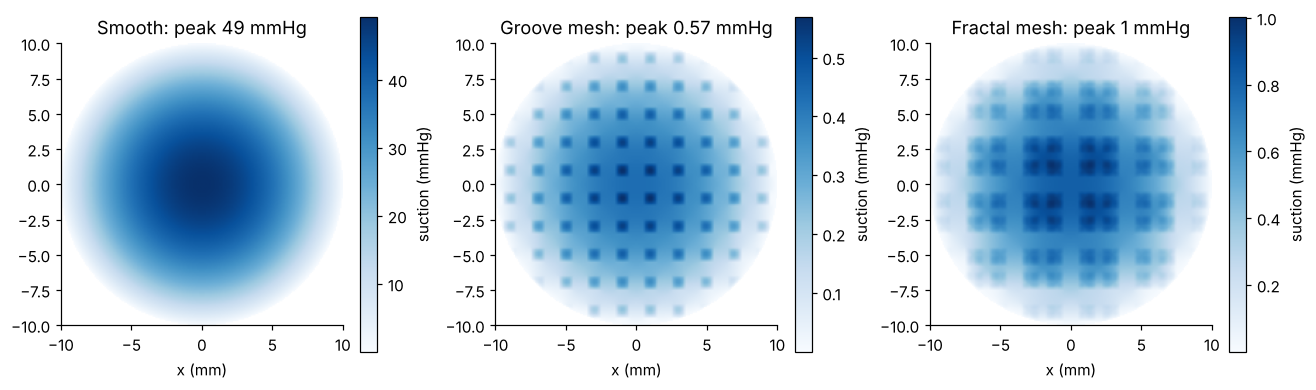

In [4]:
surfaces = {
    "Smooth": rf.recess_smooth(g),
    "Groove mesh": rf.recess_mesh(g, 2e-3, 1e-3, 2e-3),
    "Fractal mesh": rf.recess_fractal(g, 4e-3, 1e-3, 2e-3, levels=3),
}
f, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, s) in zip(axes, surfaces.items()):
    p = rf.solve(g, s, 0.2e-3, HDOT).p / MMHG
    im = ax.imshow(-p.T, origin="lower", extent=[-10, 10, -10, 10], cmap="Blues")
    ax.set_title(f"{name}: peak {np.nanmax(-p):.2g} mmHg")
    ax.set_xlabel("x (mm)")
    f.colorbar(im, ax=ax, label="suction (mmHg)")
plt.tight_layout()

**Peak suction against crest gap** (production run, 400 cells across the patch). Above about 1 mm the film does not matter; below about 0.5 mm a smooth wall needs more than the available filling gradient, and grooves keep the film near 1 mmHg.

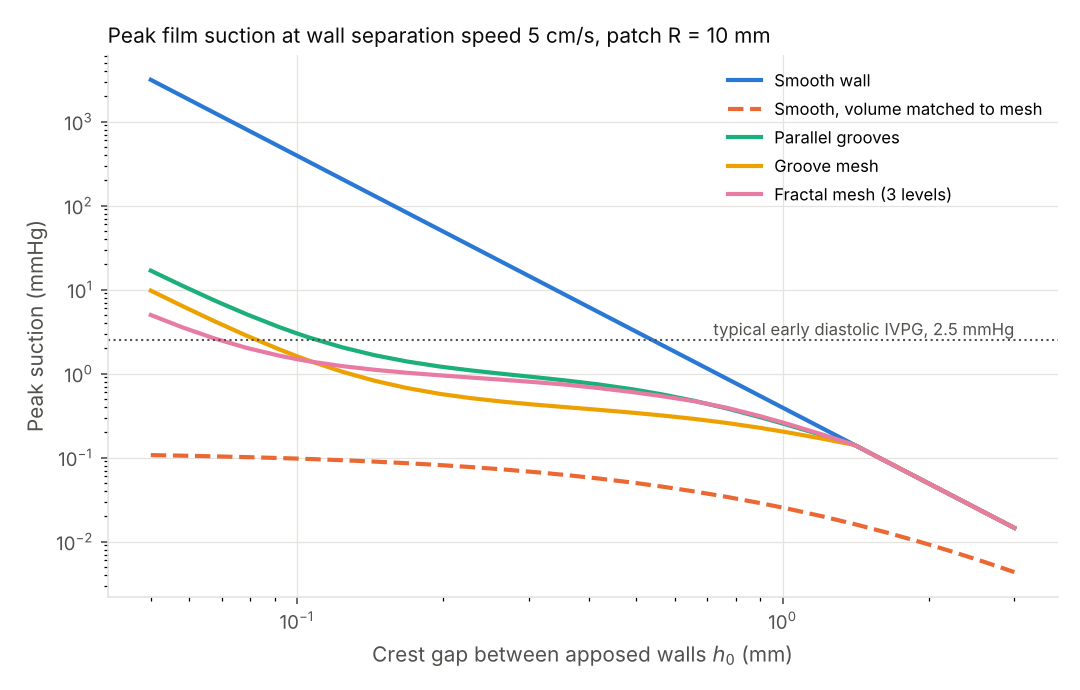

| crest gap | smooth | smooth, vol. matched | parallel | mesh | fractal | mesh relief |
|---|---|---|---|---|---|---|
| 0.1mm | 394 | 0.0974 | 3.01 | 1.61 | 1.49 | 533x |
| 0.2mm | 49.2 | 0.0812 | 1.2 | 0.567 | 0.949 | 106x |
| 0.5mm | 3.15 | 0.0497 | 0.64 | 0.34 | 0.594 | 9x |
| 1mm | 0.394 | 0.0254 | 0.255 | 0.205 | 0.262 | 2x |

In [5]:
fig("fig1_peak_suction_vs_gap.png")
rows = []
for gap, row in T1["suction_table"].items():
    rows.append(f"| {gap} | " + " | ".join(f"{row[k]['peak_mmHg']:.3g}" for k in ("smooth", "smooth_vol", "parallel", "mesh", "fractal"))
                + f" | {row['mesh']['force_reduction_vs_smooth']:.0f}x |")
display(Markdown("| crest gap | smooth | smooth, vol. matched | parallel | mesh | fractal | mesh relief |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

**Groove spacing and depth.** Relief peaks at a pitch of 3 to 4 mm, and real trabeculae (1 to 3 mm apart) sit on the rising side of that peak. A groove only drains once it is several gaps deep.

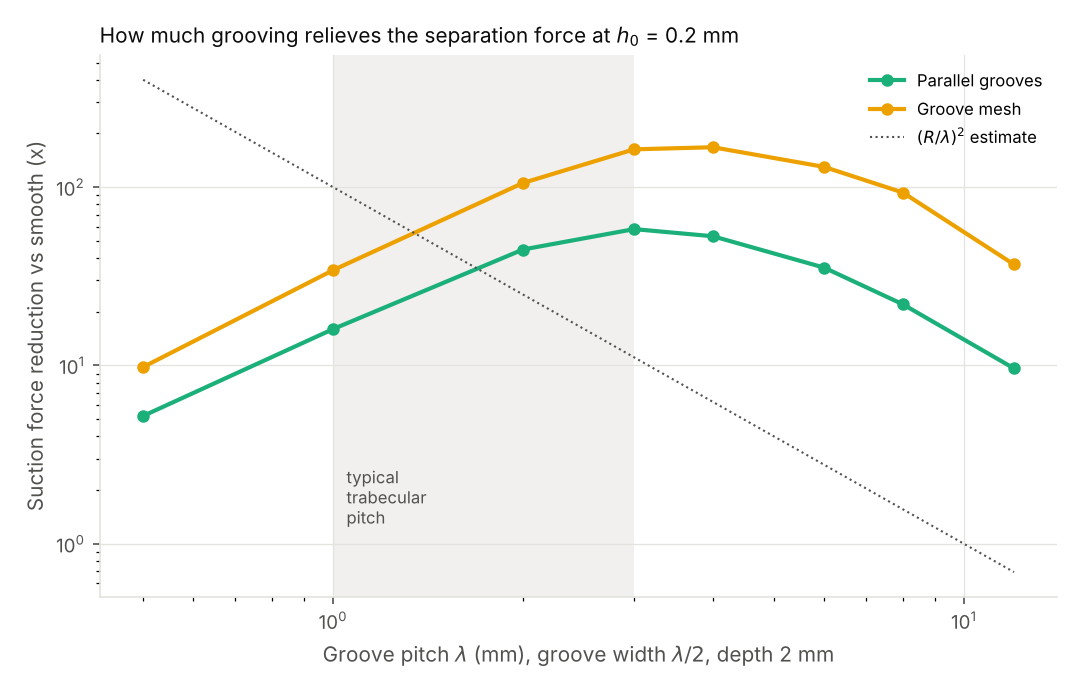

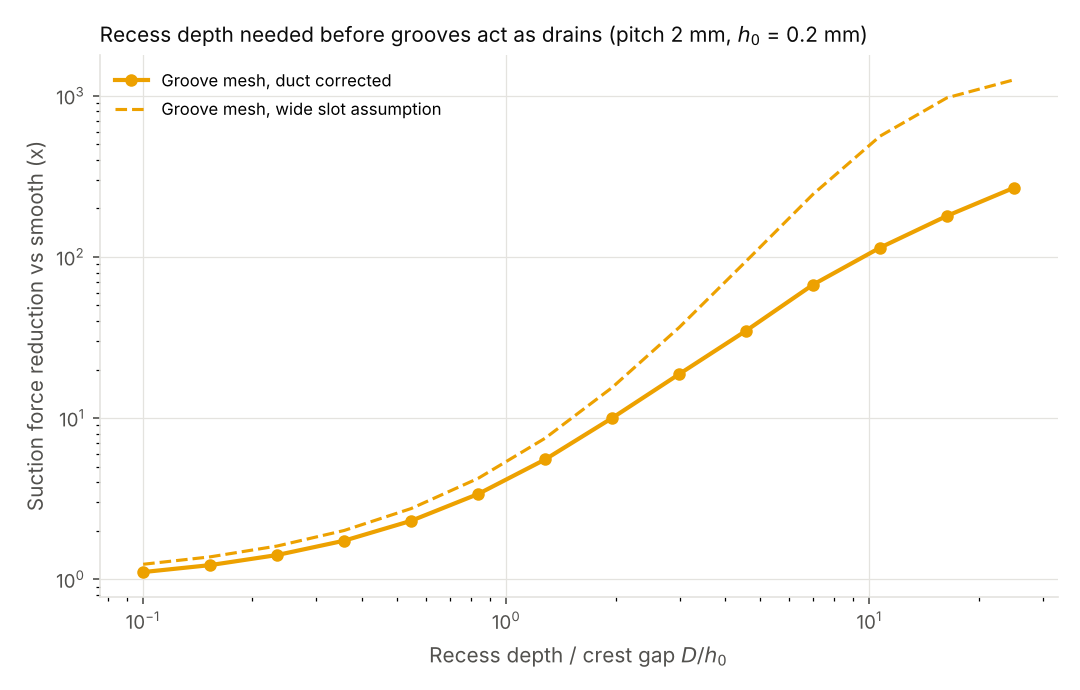

In [6]:
fig("fig2_reduction_vs_pitch.png", 600); fig("fig3_reduction_vs_depth.png", 600)

**The caveat that set up Tier 2.** Under a steady opening stress, grooved walls open far faster than a smooth wall at the same crest gap, but a smooth wall that simply empties less (the volume matched control) opens fastest of all. So the honest question is whether grooves beat emptying less, which needs filling and washout in a whole ventricle.

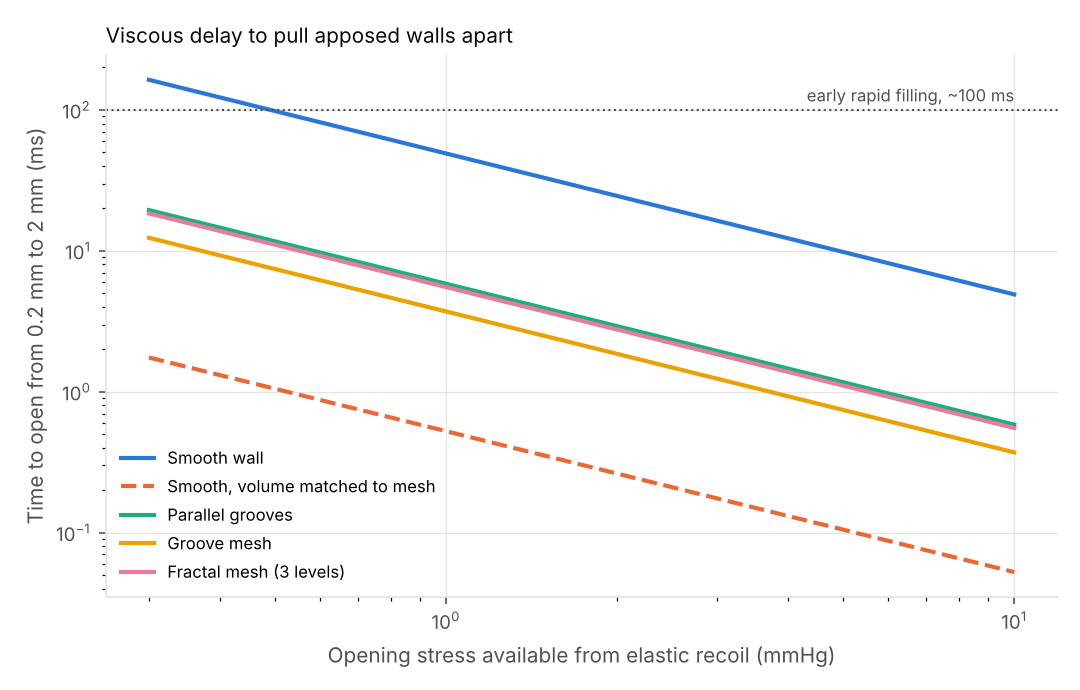

In [7]:
fig("fig4_opening_time.png", 650)

## 4. Tier 2: a 2D ventricle through full cardiac cycles

**Model** (`ventricle/`). A 2D long axis slice of the left ventricle on a 0.25 mm grid, run for three 0.8 s cycles. The incompressible Navier Stokes equations are solved pseudo spectrally, and the moving walls are imposed by Brinkman penalization (Angot et al., 1999): the wall region is treated as a porous solid whose velocity is forced to the prescribed wall motion. Mitral and aortic valves open and close on schedule, myocardial area is conserved, and the apical quarter closes to a slit at end systole. Gaps thinner than 0.75 mm cannot be resolved by the grid, so the Tier 1 film model is applied there as a subgrid closure.

**Three endocardia share one crest motion:** trabeculated (ridges with recesses), smooth at the crest (empties further), and smooth volume matched (same cavity areas as the trabeculated ventricle). The third isolates the effect of the recesses from the effect of emptying further.

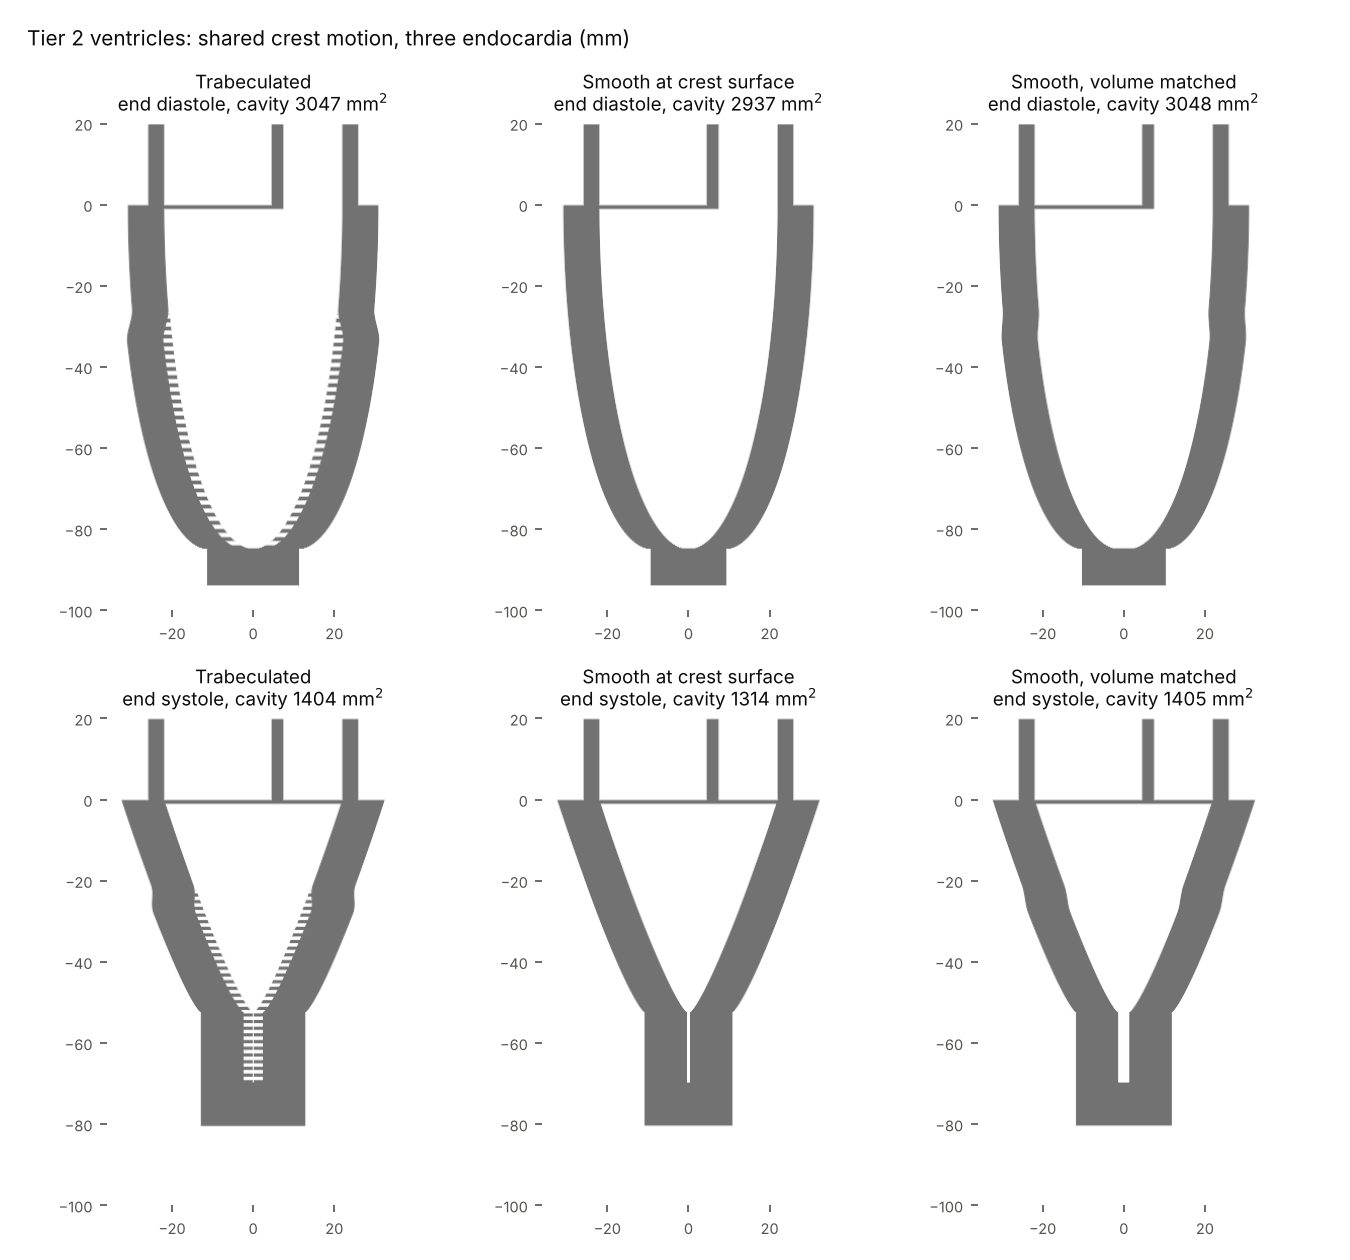

In [8]:
fig("fig6_tier2_geometry.png", 600)
display(Video("presentation/media/t2_vort.mp4", width=820, embed=False))

The video shows vorticity through one cycle: the mitral jet rolls up into a vortex that travels toward the apex, and small vortices peel off the apical slit as it reopens. The next cell tabulates the third cycle for the three ventricles.

| third cycle | Trabeculated | Smooth crest | Smooth vol. |
|---|---|---|---|
| E wave gradient (mmHg) | 2.79 | 2.33 | 2.04 |
| Dissipation per cycle (mJ/m) | 27.2 | 22 | 16.6 |
| Diastolic work (mJ/m) | -34.7 | -33.2 | -37.4 |
| Film peak, 0.2 mm gap (mmHg) | 0.212 | 6.32 | 0.0155 |
| Old blood left after 3 beats (%) | 17.2 | 17.3 | 20.7 |

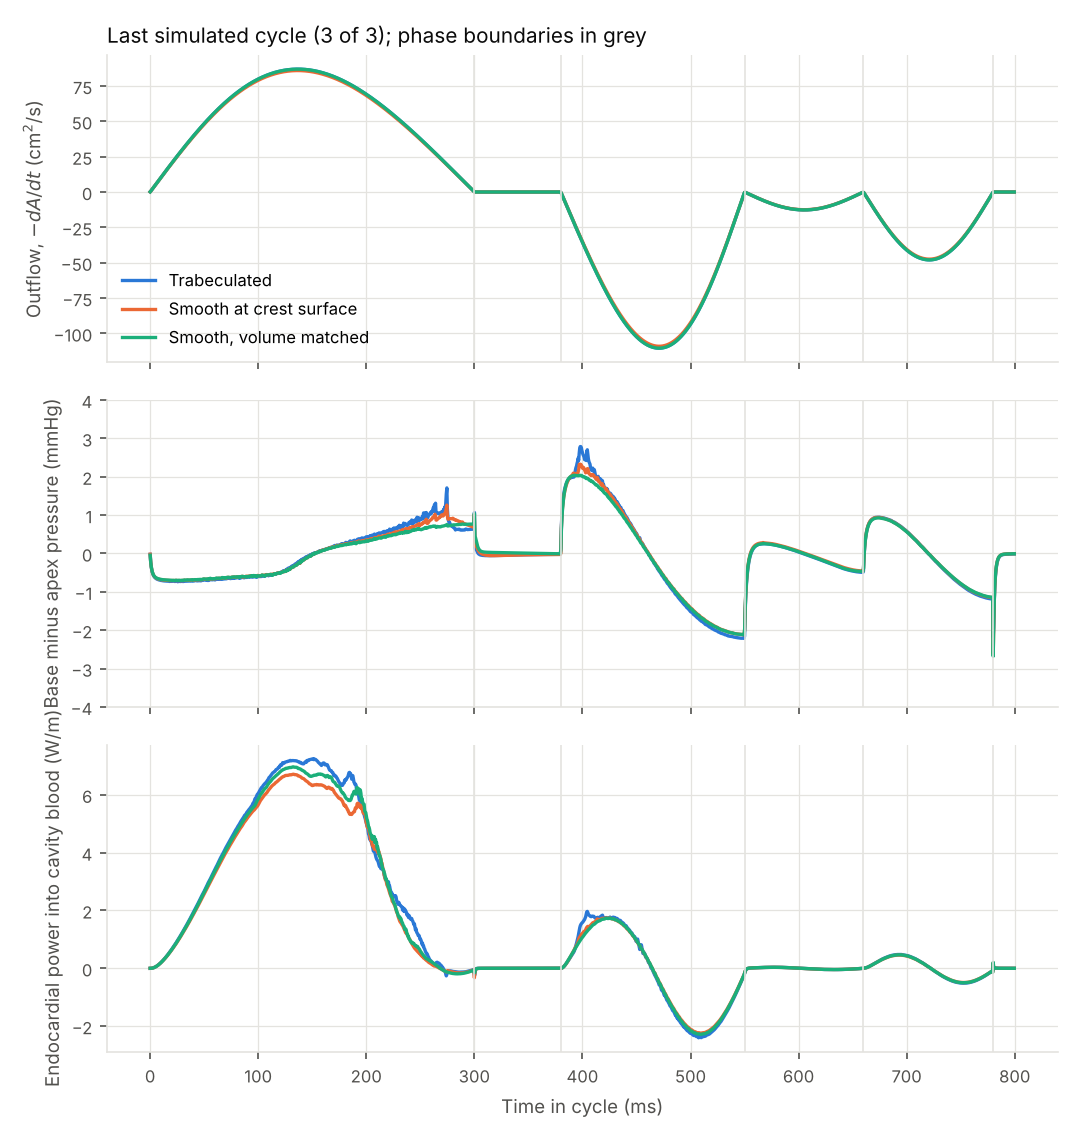

In [9]:
r = T2["resolved"]; film = T2["film"]
names = {"trab": "Trabeculated", "smooth_crest": "Smooth crest", "smooth_vol": "Smooth vol."}
lines = [
    ("E wave gradient (mmHg)", lambda k: r[k]["ivpg_peak_e_mmHg"]),
    ("Dissipation per cycle (mJ/m)", lambda k: r[k]["dissipation_cycle_mJ_per_m"]),
    ("Diastolic work (mJ/m)", lambda k: r[k]["endo_work_diastole_mJ_per_m"]),
    ("Film peak, 0.2 mm gap (mmHg)", lambda k: film[k]["0.2mm"]["film_peak_suction_mmHg"]),
    ("Old blood left after 3 beats (%)", lambda k: 100 * r[k]["residual_at_ed"][-1]),
]
tab = "| third cycle | " + " | ".join(names.values()) + " |\n|---|---|---|---|\n"
tab += "\n".join(f"| {lab} | " + " | ".join(f"{fn(k):.3g}" for k in names) + " |" for lab, fn in lines)
display(Markdown(tab))
fig("fig9_tier2_traces.png", 600)

A base to apex gradient of 2 to 3 mmHg emerges from the flow on its own, which is the physiological range. More negative diastolic work means cheaper filling (energies are per metre of depth because the model is 2D). Against the smooth crest ventricle, trabeculae remove the film penalty with the same washout. Against the volume matched ventricle they cost about 8% more filling energy but leave about 17% less old blood after three beats.

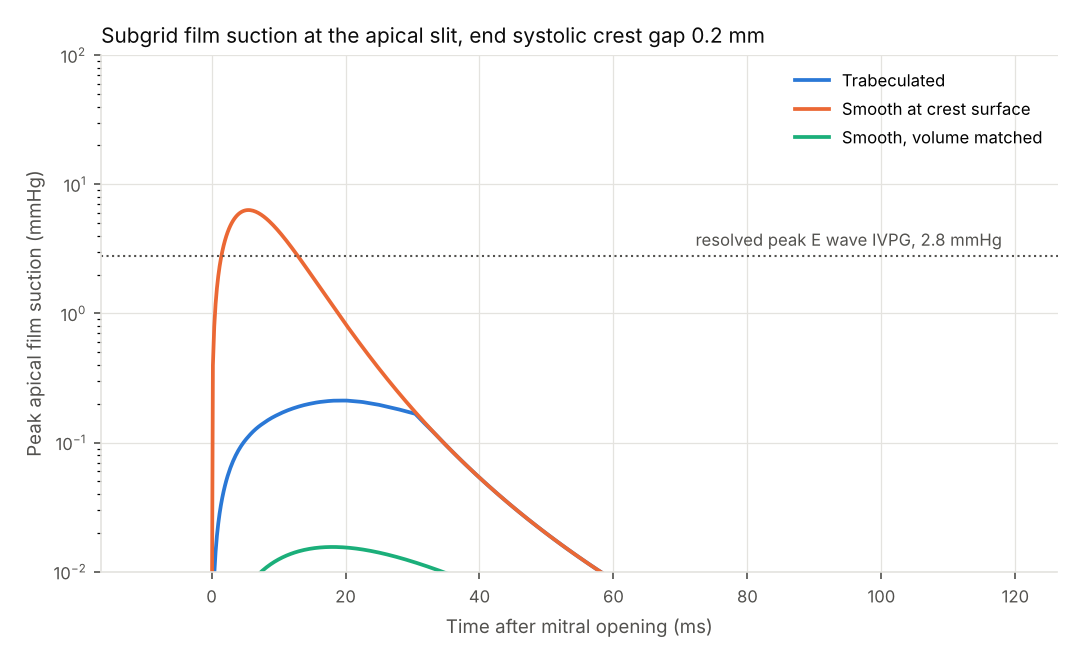

In [10]:
display(Video("presentation/media/t2_wash.mp4", width=820, embed=False))
fig("fig11_tier2_film_closure.png", 650)

**Film under forced motion.** With the walls forced to follow the Tier 2 motion, the smooth crest apex develops about 6 mmHg of film suction shortly after mitral opening (36 mmHg at a 0.1 mm gap), while the trabeculated apex stays near 0.2 mmHg. This closure is one way: it assumes the walls move on schedule regardless of the film. Tier 3 removes that assumption.

## 5. Tier 3: the apex in 3D, with walls that push back

**Resolved patch** (`apex3d/solver3d.py`, `apex3d/patch.py`). Two 12 mm walls nearly touching in open blood, on a 0.1 mm grid. One wall is smooth or carries a connected groove mesh (2 mm pitch, 1.5 mm deep). The walls are either opened at a set speed (8, 25 and 80 mm/s) or given the mass of real myocardium and pulled apart by a recoil stress while the film pushes back (two way coupling). Two solver fixes were needed first: a coupled penalization and pressure solve (walls had been moving 12% too slowly), and a viscous scaled Brinkman profile so the effective wall sits within 0.1 cell of the true surface.

**Reduced model** (`apex3d/reduced.py`). The film force is written as

$$F = -C(h)\,\dot h\,(r_0 + \kappa\,Re) - M_a(h)\,\ddot h, \qquad Re = \rho\,\dot h\,h/\mu,$$

where $C(h)$ is the Tier 1 viscous resistance, $M_a(h)$ is the added mass of the film (the blood the walls must accelerate with them, from the inertial form of the Reynolds equation), and $r_0$, $\kappa$ are fitted to the resolved runs. $r_0 = 1$ would mean Tier 1 is exact at low Reynolds number.

smooth: resolved/Tier1 = 1.14 -0.026 Re  (rms 0.08, 6 windows, Re 2 to 33)
mesh  : resolved/Tier1 = 0.79 -0.007 Re  (rms 0.12, 6 windows, Re 2 to 33)


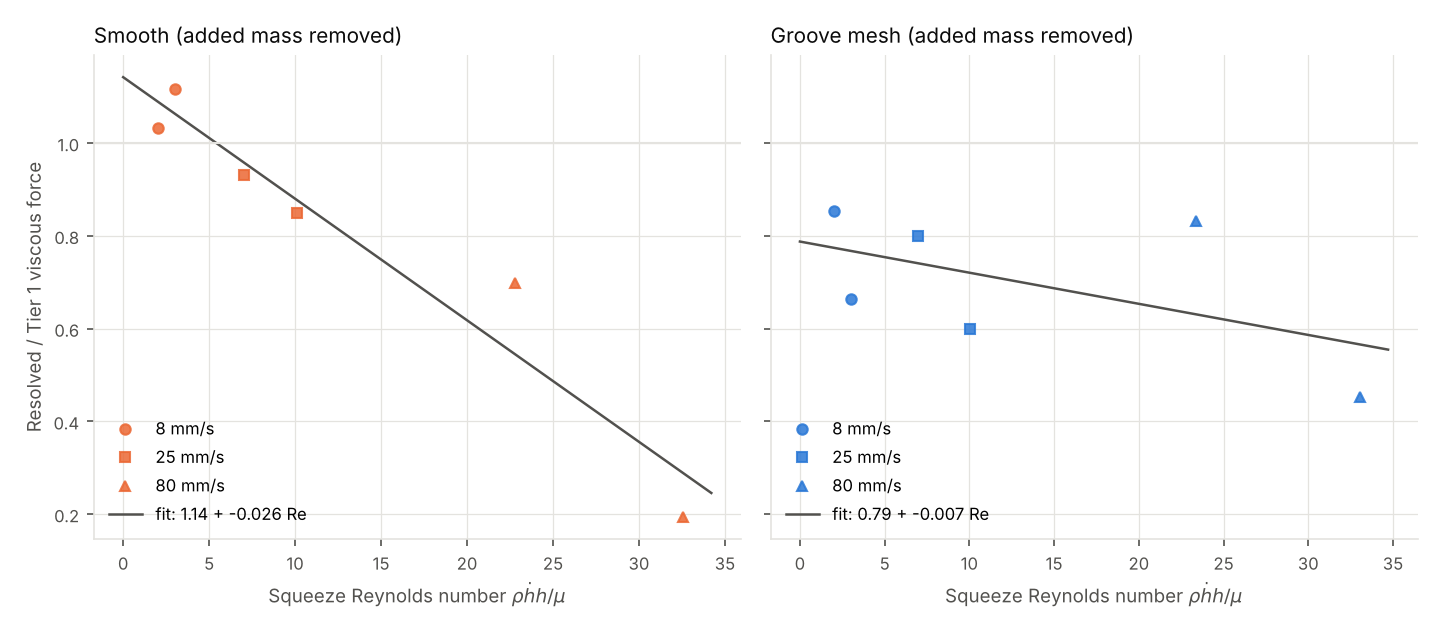

In [11]:
display(Video("presentation/media/t3_open3d.mp4", width=820, embed=False))
display(Video("presentation/media/t3_slice.mp4", width=820, embed=False))
cal = T3["calibration"]
for s in ("smooth", "mesh"):
    c = cal[s]
    print(f"{s:6s}: resolved/Tier1 = {c['r0']:.2f} {c['kappa']:+.3f} Re  (rms {c['rms']:.2f}, {c['n']} windows, Re {c['re_range'][0]:.0f} to {c['re_range'][1]:.0f})")
fig("fig12_tier3_inertia_calibration.png")

For the smooth wall Tier 1 is right to within about 7% at low Reynolds number, and inertia lowers the suction slightly rather than raising it. The real 3D groove network drains about 20% better than Tier 1 assumed ($r_0 \approx 0.79$). The two way coupled runs then test the reduced model on wall dynamics it was not fitted to: it predicts the resolved opening times within 6 to 8%, while quasi static Tier 1 opens 72 to 84% too fast.

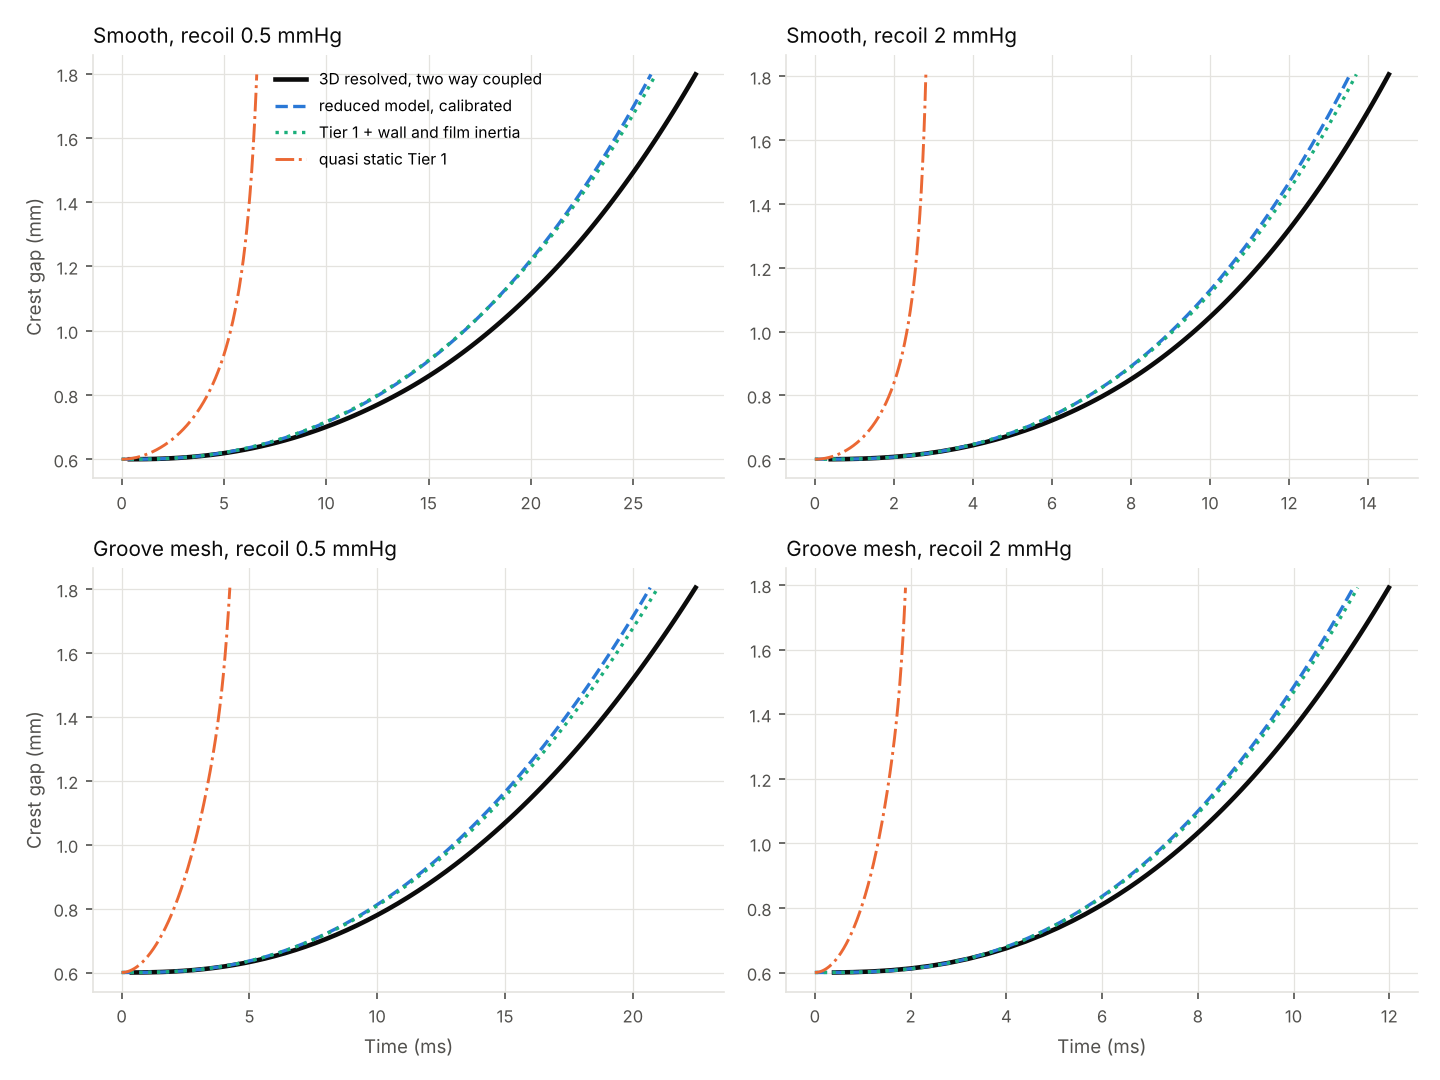

In [12]:
fig("fig13_tier3_fsi_validation.png", 650)

**Physiological gaps, recomputed live.** With the model validated, we carry it to the 0.1 to 0.2 mm gaps that no grid here can resolve. The cell below rebuilds the calibrated models and opens the apex under a 2 mmHg recoil (rising over 20 ms) from a 0.2 mm gap, with walls of 10.6 kg/m^2 (about 10 mm of myocardium each), timing how long each takes to reach 2 mm. "Walls only" removes the film altogether and is the fastest possible opening. This uses a coarser grid than the production run, so expect small differences from the saved table printed underneath.

saved production run, ms to open to 2 mm: {'walls only': 17, 'trab': 24, 'smooth_crest': 54, 'smooth_vol': 21}


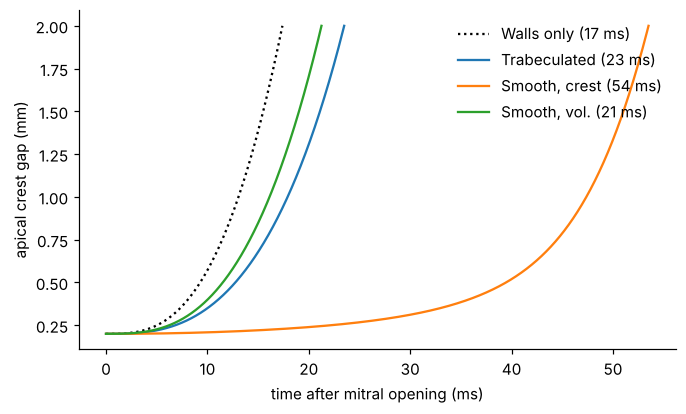

In [13]:
R_PATCH, M_WALL, H_OPEN, h0 = 8.75e-3, 10.6, 2e-3, 0.2e-3
kw = lambda s: dict(kappa=cal[s]["kappa"], r0=cal[s]["r0"])
models = {
    "Trabeculated": FilmModel.build(surface="mesh", R=R_PATCH, depth=2e-3, n=100, **kw("mesh")),
    "Smooth, crest": FilmModel.build(surface="smooth", R=R_PATCH, n=100, **kw("smooth")),
    "Smooth, vol.": FilmModel.build(surface="smooth", R=R_PATCH, n=100, extra_gap=2e-3, **kw("smooth")),
}
free = FilmModel.build(surface="smooth", R=R_PATCH, n=60, h=np.geomspace(1e-3, 1.0, 12))
free.C, free.Ma = free.C * 1e-12, free.Ma * 1e-12
sig = recoil(2.0 * MMHG, 20e-3)
plt.figure(figsize=(7, 4))
res = open_walls(free, sig, M_WALL, h0, H_OPEN)
plt.plot(res["t"] * 1e3, res["h"] * 1e3, "k:", label=f"Walls only ({1e3*time_to_gap(res, H_OPEN):.0f} ms)")
for name, m in models.items():
    res = open_walls(m, sig, M_WALL, h0, H_OPEN)
    plt.plot(res["t"] * 1e3, res["h"] * 1e3, label=f"{name} ({1e3*time_to_gap(res, H_OPEN):.0f} ms)")
plt.xlabel("time after mitral opening (ms)"); plt.ylabel("apical crest gap (mm)"); plt.legend(frameon=False)

saved = T3["physiology"]["2mmHg_0.2mm"]
print("saved production run, ms to open to 2 mm:",
      {"walls only": round(saved["no_film_ms"]), **{k: round(saved[k]["open_ms"]) for k in ("trab", "smooth_crest", "smooth_vol")}})

The smooth crest apex reopens tens of milliseconds late (189 ms late at 1 mmHg and a 0.1 mm gap), while the trabeculated apex stays within 3 to 9 ms of the walls only limit. Under pressure driven motion, then, the smooth wall's penalty shows up as delay rather than just suction, and the prescribed Tier 2 motion for that ventricle was physically unreachable. The trabeculated and volume matched walls both open faster than Tier 2 assumed, so their Tier 2 results stand.

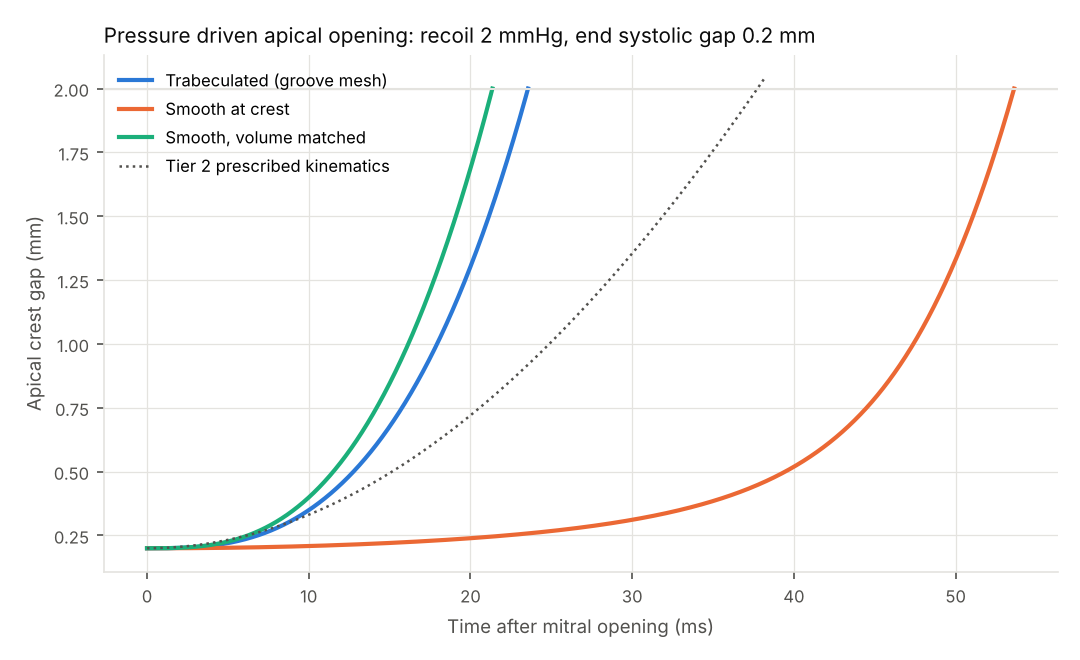

In [14]:
fig("fig14_tier3_apical_opening.png", 650)

## 6. Verdict, limits and references

**Verdict.** Trabeculae let the apex empty to near contact and still reopen on time. The film is real (a smooth wall at a few tenths of a millimetre needs far more pressure to reopen than diastole supplies, and the 3D runs confirm Tier 1); grooves drain it (to about 1 mmHg, and better in 3D than Tier 1 predicted); and the cost to a smooth apex is delay. Against a smooth heart that simply empties less, trabeculae cost slightly more filling energy but wash out old blood better. This is a narrower and more defensible form of the textbook claim: not "trabeculae prevent suction" but "trabeculae permit near apposition without adhesion".

**Limits.** Tier 2 is a 2D slice with prescribed wall motion. Tier 3 is a 12 mm patch with one grooved, rigid wall. Recoil stress and wall mass are order of magnitude estimates. The calibration rests on six windows per surface with 8 to 12% scatter. The single most important unknown is how close real apical walls come at end systole, since everything hinges on whether that gap falls below about half a millimetre.

**Next steps.** Let the Tier 2 apex open under recoil instead of on a schedule; groove both walls with irregular, tapered recesses; build a 3D ventricle from trabecular resolution imaging (ex vivo MRI or CT); and measure end systolic apical gaps in vivo.

**References**

- Angot, P., Bruneau, C. H., & Fabrie, P. (1999). A penalization method to take into account obstacles in incompressible viscous flows. *Numerische Mathematik, 81*, 497 to 520.
- Battista, N. A., et al. (2018). Fluid dynamics in heart development: Effects of hematocrit and trabeculation. *Mathematical Medicine and Biology*. https://doi.org/10.1093/imammb/dqx018
- Kulp, S., et al. (2011). Patient specific modeling and analysis of the interactions between trabeculae and blood flow. *MICCAI 2011*. https://doi.org/10.1007/978-3-642-23623-5_59
- Lantz, J., et al. (2016). Patient specific simulation of cardiac blood flow from high resolution computed tomography. *Journal of Biomechanical Engineering*. https://doi.org/10.1115/1.4034652
- Lee, J., et al. (2018). Hemodynamic forces initiate cardiac trabeculation. *JCI Insight*. https://doi.org/10.1172/jci.insight.96672
- Meyer, H. V., et al. (2020). Genetic and functional insights into the fractal structure of the heart. *Nature*. https://doi.org/10.1038/s41586-020-2635-8
- Paun, B., et al. (2018). Relationship between the left ventricular size and the amount of trabeculations. *International Journal for Numerical Methods in Biomedical Engineering*. https://doi.org/10.1002/cnm.2939
- Reynolds, O. (1886). On the theory of lubrication. *Philosophical Transactions of the Royal Society of London, 177*, 157 to 234.
- Sacco, F., et al. (2018). Left ventricular trabeculations decrease the wall shear stress and increase the intraventricular pressure drop in CFD simulations. *Frontiers in Physiology*. https://doi.org/10.3389/fphys.2018.00458
- Stefan, J. (1874). Versuche über die scheinbare Adhäsion. *Sitzungsberichte der Kaiserlichen Akademie der Wissenschaften in Wien, 69*, 713 to 735.
- Vedula, V., et al. (2017). A method to quantify mechanobiologic forces during zebrafish cardiac development using 4D light sheet imaging and computational modeling. *PLoS Computational Biology*. https://doi.org/10.1371/journal.pcbi.1005828

Full write ups: `RESULTS.md`, `RESULTS_TIER2.md`, `RESULTS_TIER3.md`.